# TP2 Machine Learning
## Les réseaux de neurones

- **Realisé Par : Houda HAJJAJ et Abdelfatah CHAIB**
- **M2 EUR Smart IoT** 

### Objectif du TP

Ce TP a pour objectif d'étudier le fonctionnement des réseaux de neurones à travers l'implémentation d'un perceptron simple, son apprentissage et la réalisation d'un perceptron multicouche.

Le TP est réalisé progressivement selon les parties du sujet :

1. **Développement d'un perceptron simple :** définition du modèle et test sur la fonction logique OU.
2. **Apprentissage du perceptron :** implémentation de l'algorithme de Widrow-Hoff et expérimentation sur deux jeux de données.
3. **Perceptron multicouche :** propagation des entrées dans le réseau, apprentissage des poids et analyse des résultats.

## 1. Développement d'un perceptron simple

### 1.1. Mise en place d'un perceptron simple

Dans cette première partie, nous allons implémenter un perceptron simple, un modèle de base utilisé pour la classification binaire.

Le perceptron reçoit un vecteur d'entrée, associe un poids à chaque entrée et ajoute un biais. Il calcule ensuite une somme pondérée, puis applique une fonction d'activation pour obtenir sa sortie.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

### Principe mathématique

Pour deux entrées \(x_1\) et \(x_2\), le perceptron utilise trois paramètres : le biais \(w_0\) et les poids \(w_1\) et \(w_2\).

La somme pondérée est :

$
z = w_0 + w_1x_1 + w_2x_2
$

Pour intégrer le biais au calcul, on ajoute une composante égale à 1 au vecteur d'entrée :
$
x_{\mathrm{aug}} = [1, x_1, x_2]
$
Le calcul devient alors un produit scalaire :

$
z = w \cdot x_{\mathrm{aug}}
$

La sortie du perceptron est obtenue en appliquant la fonction d'activation à \(z\).

In [2]:
def perceptron_simple(x, w, active):
    # Ajouter le biais à l'entrée
    x_aug = np.insert(x, 0, 1)

    # Calculer la somme pondérée
    z = np.dot(w, x_aug)

    # Fonction d'activation
    if active == 0:
        y = np.sign(z)
    elif active == 1:
        y = np.tanh(z)
    else:
        raise ValueError("active doit être 0 (sign) ou 1 (tanh).")

    return y

### Vérification de l'implémentation

Avant d'utiliser le perceptron sur un problème de classification, nous allons vérifier son fonctionnement sur quelques entrées simples.
Cette vérification permet de contrôler l'ajout du biais, le calcul de la somme pondérée et le comportement des deux fonctions d'activation.

In [3]:
# Exemple de paramètres
x = np.array([1, 2])
w = np.array([-0.5, 1, 1])

# Test avec la fonction sign
y_sign = perceptron_simple(x, w, active=0)

# Test avec la fonction tanh
y_tanh = perceptron_simple(x, w, active=1)

print("Entrée :", x)
print("Poids :", w)
print("Sortie avec sign :", y_sign)
print("Sortie avec tanh :", y_tanh)

Entrée : [1 2]
Poids : [-0.5  1.   1. ]
Sortie avec sign : 1.0
Sortie avec tanh : 0.9866142981514303


### 1.2. Test du perceptron sur la fonction logique OU

Dans cette étape, nous allons tester le perceptron simple sur la fonction logique OU (*OR*).

La fonction OU renvoie 1 lorsqu'au moins une des deux entrées vaut 1, et 0 uniquement lorsque les deux entrées valent 0. Nous allons définir les quatre combinaisons possibles, calculer les sorties du perceptron et comparer les prédictions aux sorties attendues.

In [4]:
def afficher_resultats(X, Y, w):

    # Affichage des points de chaque classe
    plt.scatter(
        X[Y == -1, 0], X[Y == -1, 1],
        color="red", label="Classe -1"
    )

    plt.scatter(
        X[Y == 1, 0], X[Y == 1, 1],
        color="green", label="Classe +1"
    )

    # Tracer la droite séparatrice : z = a*x + b
    t = [-0.5, 1.5]

    a = -w[1] / w[2]  # Pente de la droite
    b = -w[0] / w[2]  # Ordonnée à l'origine
    z = [a * t[0] + b, a * t[1] + b]

    # Tracé de la droite de séparation
    plt.plot(t, z, color="blue", label="Droite séparatrice")

    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.title("Perceptron simple - Fonction OU logique")
    plt.legend()
    plt.grid(True)
    plt.show()

Test du perceptron sur l'exemple du OU logique.
Entrée : [0 0] - Sortie prédite : -1.0 - Sortie attendue : -1
Entrée : [0 1] - Sortie prédite : 1.0 - Sortie attendue : 1
Entrée : [1 0] - Sortie prédite : 1.0 - Sortie attendue : 1
Entrée : [1 1] - Sortie prédite : 1.0 - Sortie attendue : 1


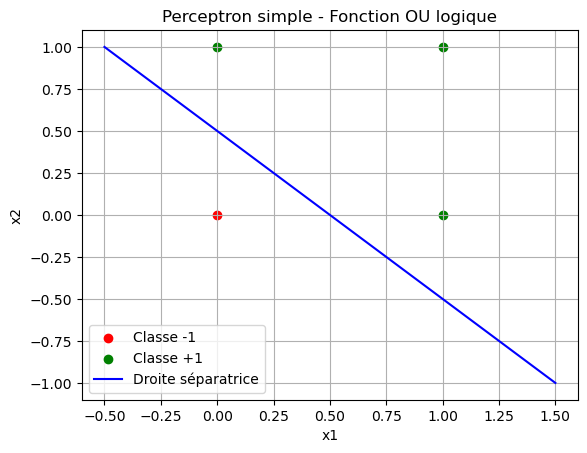

In [5]:
def test_perceptron_ou_logique():

    # Définition des données du OU logique
    X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
    Y = np.array([-1, 1, 1, 1])  # Sorties attendues avec sign

    # Définition des poids du perceptron : biais + w1 + w2
    w = np.array([-0.5, 1, 1])

    print("Test du perceptron sur l'exemple du OU logique.")

    for i in range(len(X)):
        y_pred = perceptron_simple(X[i], w, active=0)

        print(
            f"Entrée : {X[i]} - "
            f"Sortie prédite : {y_pred} - "
            f"Sortie attendue : {Y[i]}"
        )

    afficher_resultats(X, Y, w)


# Test du OU logique
test_perceptron_ou_logique()

## 2. Implémentation de l'algorithme de Widrow-Hoff

Dans cette étape, nous allons implémenter l'algorithme de Widrow-Hoff afin d'apprendre automatiquement les poids du perceptron à partir des données.

Les poids sont initialisés aléatoirement. À chaque époque, les données sont parcourues par batches, les prédictions sont calculées et les poids sont mis à jour en fonction de l'erreur. L'apprentissage s'arrête lorsque l'erreur cumulée devient nulle ou lorsque le nombre maximal d'époques est atteint.

In [6]:
def apprentissage_widrow(x, yd, epoch, batch_size):
    # Nombre d'exemples d'apprentissage
    n_samples = x.shape[1]

    # Initialisation aléatoire des poids : biais, poids de x1 et poids de x2
    w = np.random.rand(3)

    # Liste pour enregistrer l'erreur à chaque époque
    erreur = []

    # Ajout de la ligne de biais
    x_bias = np.vstack((np.ones((1, n_samples)), x))

    # Apprentissage sur plusieurs époques
    for ep in range(epoch):
        erreur_epoch = 0

        # Traitement des données par batches
        for i in range(0, n_samples, batch_size):

            # Sélection du batch
            x_batch = x_bias[:, i:i + batch_size]
            yd_batch = yd[i:i + batch_size]

            # Prédiction du perceptron
            y_pred = np.sign(w @ x_batch)

            # Éviter une sortie nulle
            y_pred[y_pred == 0] = 1

            # Erreur entre les sorties désirées et prédites
            erreur_batch = yd_batch - y_pred

            # Mise à jour des poids
            w += (1 / batch_size) * np.dot(x_batch, erreur_batch)

            # Accumulation de l'erreur quadratique
            erreur_epoch += np.sum(erreur_batch ** 2)

        # Affichage des classes et de la frontière de décision
        affiche_classe(
            w, x, yd,
            f"Epoch {ep + 1} (erreur : {erreur_epoch})"
        )

        # Enregistrement de l'erreur
        erreur.append(erreur_epoch)

        # Arrêt si l'erreur est nulle
        if erreur_epoch == 0:
            break

    return w, erreur

### 2.2. Visualisation des résultats

La fonction `affiche_classe` représente les exemples des deux classes dans un plan. Elle trace également la frontière de décision définie par les poids du perceptron.

La frontière correspond à l'équation :

$
w_0+w_1x_1+w_2x_2=0
$

Cette représentation permet de vérifier visuellement si la séparation des classes est cohérente avec les données.

In [7]:
def affiche_classe(w, x, yd, titre):
    plt.figure(figsize=(7, 5))

    # Affichage des points d'apprentissage
    for i in range(x.shape[1]):
        if yd[i] == 1:
            plt.scatter(
                x[0, i], x[1, i],
                color="green", marker="o"
            )
        else:
            plt.scatter(
                x[0, i], x[1, i],
                color="red", marker="x"
            )

    # Tracé de la frontière de décision
    if w is not None and w[2] != 0:
        t = np.linspace(x[0, :].min(), x[0, :].max(), 100)

        a = -w[1] / w[2]
        b = -w[0] / w[2]

        z = a * t + b

        plt.plot(t, z, color="blue", label="Frontière de décision")
        plt.legend()
    else:
        print("Impossible de tracer la droite : division par zéro.")

    plt.title(titre)
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.grid(True)
    plt.show()

### 2.3. Test 1 : apprentissage sur `p2_d1.txt`

Dans ce premier test, nous chargeons le jeu de données `p2 d1.txt`, appliquons l'algorithme de Widrow-Hoff et observons l'évolution de l'erreur ainsi que la frontière de décision obtenue.

In [8]:
# Charger les données
data1 = np.loadtxt("p2_d1.txt")

# Séparer les entrées et les sorties désirées
x1 = data1[:, :2].T
yd1 = data1[:, 2]

print("Dimensions des entrées :", x1.shape)
print("Dimensions des sorties :", yd1.shape)
print("Classes présentes :", np.unique(yd1))

Dimensions des entrées : (2, 2)
Dimensions des sorties : (2,)
Classes présentes : [-1.3904626  2.731644 ]


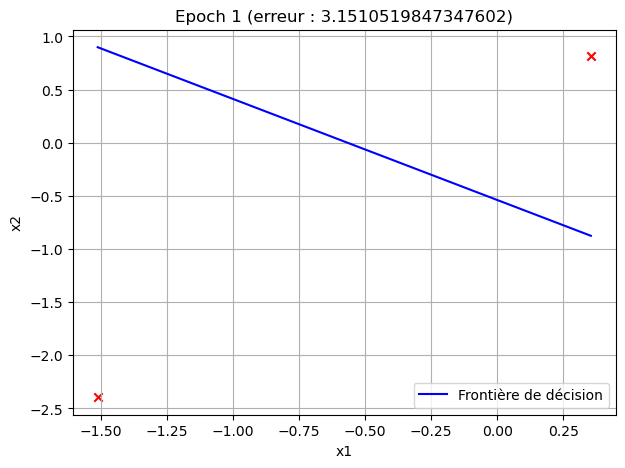

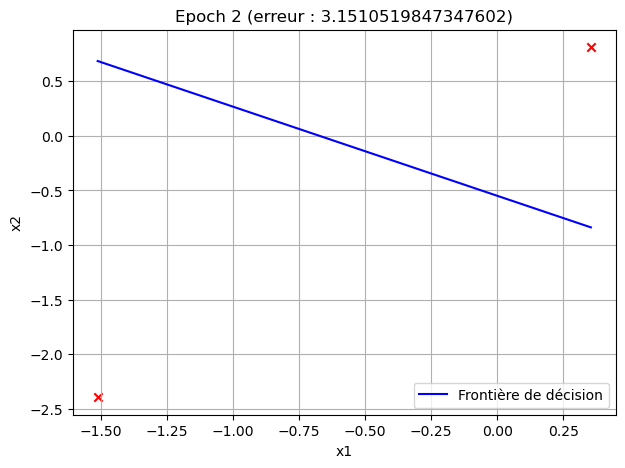

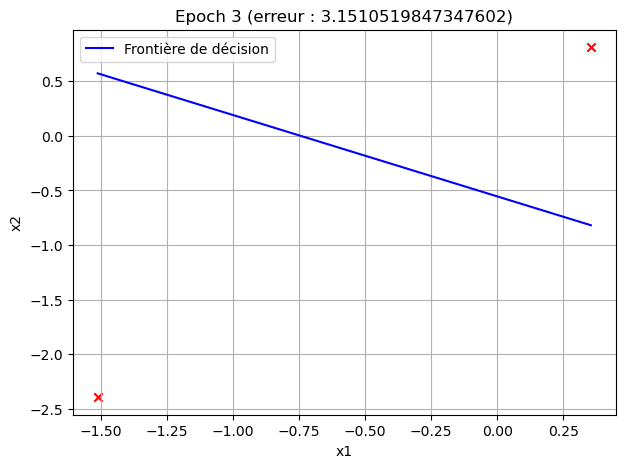

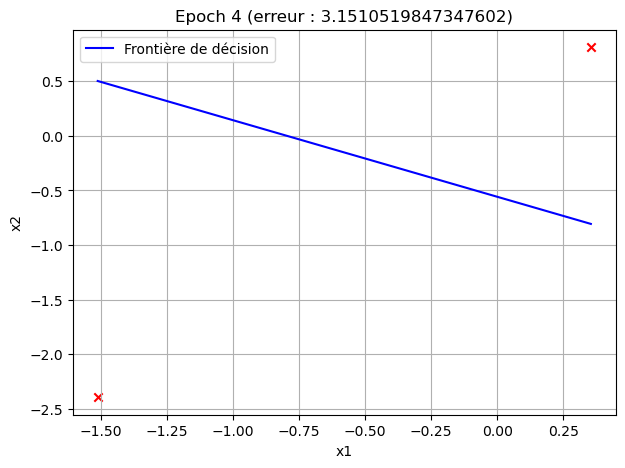

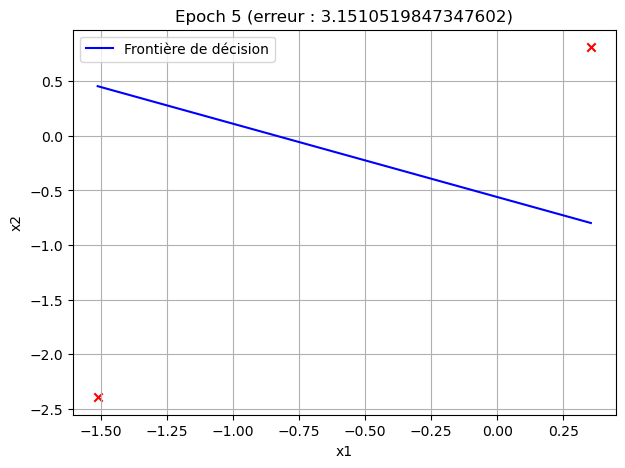

Poids appris : [2.05101687 2.45620461 3.65865819]
Dernière erreur : 3.1510519847347602


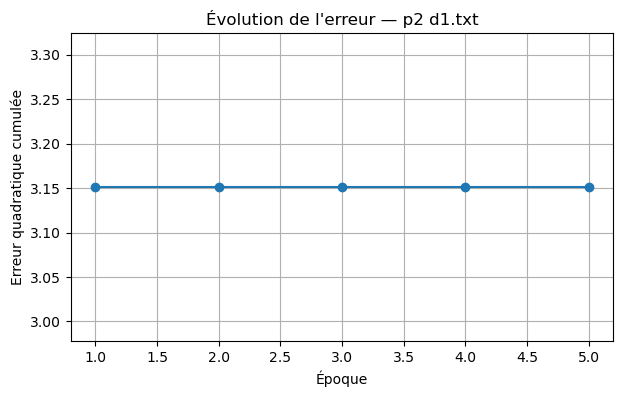

In [9]:
np.random.seed(42)

w1, erreur1 = apprentissage_widrow(
    x1, yd1,
    epoch=5,
    batch_size=4
)

print("Poids appris :", w1)
print("Dernière erreur :", erreur1[-1])

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(erreur1) + 1), erreur1, marker="o")
plt.xlabel("Époque")
plt.ylabel("Erreur quadratique cumulée")
plt.title("Évolution de l'erreur — p2 d1.txt")
plt.grid(True)
plt.show()

### 2.4. Test 2 : apprentissage sur `p2_d2.txt`

Nous répétons la même démarche avec le deuxième jeu de données. Nous comparerons les erreurs et les frontières de décision afin d'évaluer la capacité du perceptron à séparer les classes dans chaque cas.

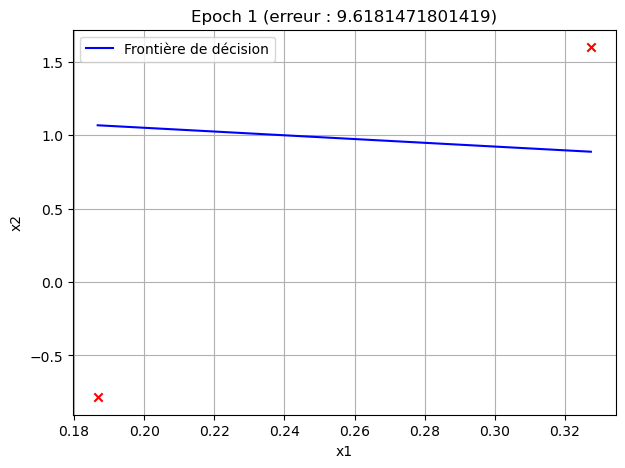

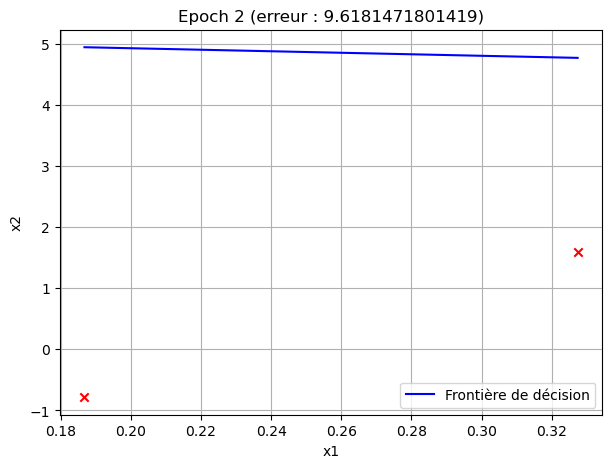

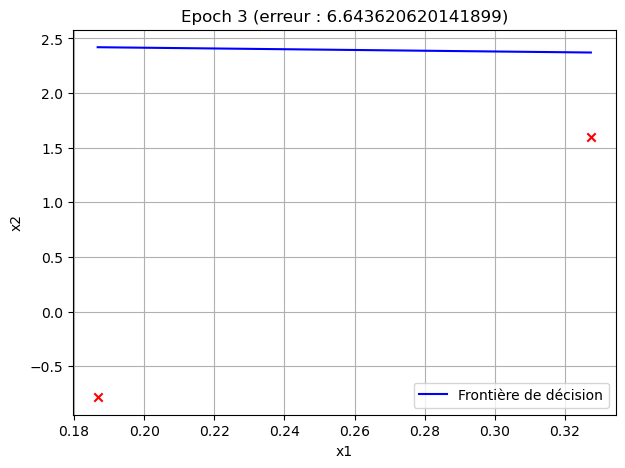

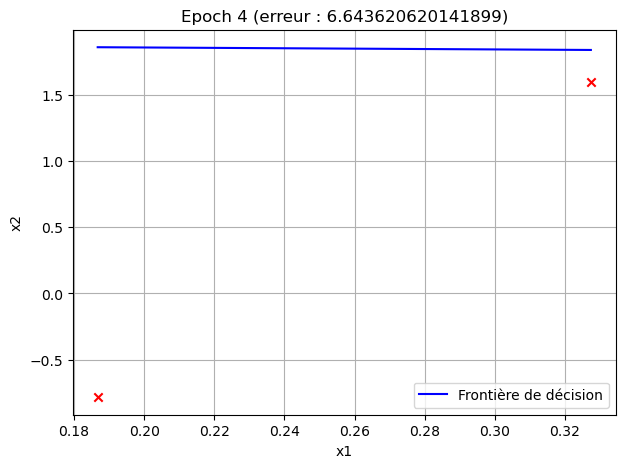

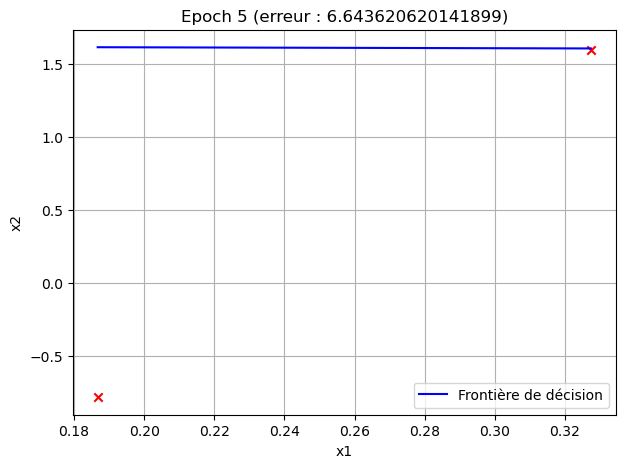

Poids appris : [-3.51092556  0.12953256  2.15920211]
Dernière erreur : 6.643620620141899


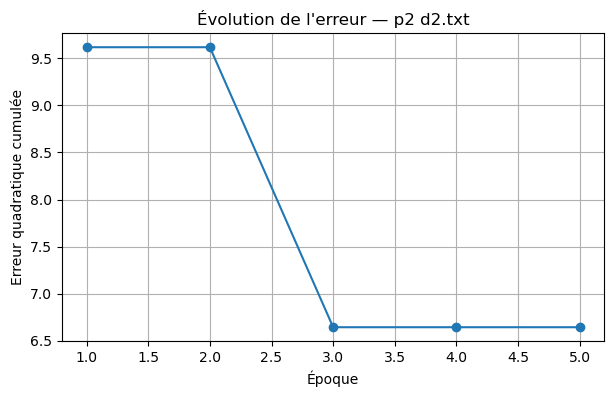

In [10]:
# Charger les données
data2 = np.loadtxt("p2_d2.txt")

# Séparer les entrées et les sorties désirées
x2 = data2[:, :2].T
yd2 = data2[:, 2]

np.random.seed(42)

w2, erreur2 = apprentissage_widrow(
    x2, yd2,
    epoch=5,
    batch_size=4
)

print("Poids appris :", w2)
print("Dernière erreur :", erreur2[-1])

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(erreur2) + 1), erreur2, marker="o")
plt.xlabel("Époque")
plt.ylabel("Erreur quadratique cumulée")
plt.title("Évolution de l'erreur — p2 d2.txt")
plt.grid(True)
plt.show()

### 2.5. Comparaison des deux jeux de données

Après cinq époques d'apprentissage, les erreurs finales obtenues sont :

- **`p2_d1.txt` :** erreur de 3,15.
- **`p2_d2.txt` :** erreur de 6,64.

Le jeu de données `p2_d1.txt` présente une erreur finale de `3,15`, contre `6,64` pour `p2_d2.txt`. Le premier jeu de données donne donc une erreur plus faible, d'environ `52,6 %`.

Cependant, l'erreur reste non nulle dans les deux cas après cinq époques : la convergence n'est pas atteinte. L'apprentissage est donc meilleur sur p2_d1.txt selon le critère de l'erreur, mais ces résultats seuls ne permettent pas de conclure sur la séparabilité des classes.

## 3. Perceptron multicouche

### 3.1. Implémentation du réseau

Dans cette partie, nous implémentons un perceptron multicouche avec deux neurones dans la couche cachée et un neurone de sortie. Nous utilisons la fonction sigmoïde pour calculer les activations des neurones.

$
\varphi(v)=\frac{1}{1+e^{-v}}
$

Le seuil de chaque neurone est représenté par un poids associé à une entrée constante égale à \(1\).

Le réseau sera testé avec l’entrée \(x=(1,1)\), puis le résultat obtenu par programmation sera comparé au calcul manuel.
L'objectif est de comprendre la propagation des entrées dans le réseau avant de programmer l'apprentissage des poids.

In [11]:
def multiperceptron(X, w1, w2):
    # Ajouter le biais aux entrées
    X_biais = np.vstack((np.ones((1, X.shape[1])), X))

    # Calcul des sorties de la couche cachée
    z = w1.T @ X_biais

    # Fonction d'activation sigmoïde
    a = 1 / (1 + np.exp(-z))

    # Ajouter le biais à la couche cachée
    ah = np.vstack((np.ones((1, X.shape[1])), a))

    # Calcul de la sortie du réseau
    z_out = w2 @ ah

    # Fonction d'activation de sortie
    y = 1 / (1 + np.exp(-z_out))

    return y

### 3.2. Test de la propagation avant

Nous testons le réseau avec des poids initialisés pour vérifier que les calculs s'exécutent correctement et que les sorties sont comprises entre 0 et 1. À ce stade, les poids ne sont pas encore appris : ce test vérifie uniquement le fonctionnement du réseau.

In [12]:
# Deux exemples d'entrée
X_test = np.array([
    [0, 1],
    [0, 1]
])

# Initialisation des poids
np.random.seed(42)
w1_test = np.random.rand(3, 2)
w2_test = np.random.rand(3)

# Propagation avant
y_test = multiperceptron(X_test, w1_test, w2_test)

print("Sorties du réseau :")
print(y_test)

Sorties du réseau :
[0.73202101 0.77589839]


### 3.3. Apprentissage du perceptron multicouche

Nous allons maintenant entraîner le réseau à partir des données d'apprentissage. À chaque itération, nous calculons les activations de la couche cachée et de la sortie, puis l'erreur entre la prédiction et la cible. Cette erreur est rétropropagée pour mettre à jour les poids des deux couches.

Le taux d'apprentissage indiqué dans le sujet est $(\alpha=0.5$). Nous suivrons l'évolution de l'erreur pour évaluer l'apprentissage.

In [13]:
def multiperceptron_widraw(x, yd, Epoch, batch_size):

    # Initialiser les poids synaptiques
    # w1 : poids de la couche cachée (biais inclus)
    # w2 : poids de la couche de sortie (biais inclus)
    w1 = np.random.rand(3, 2)
    w2 = np.random.rand(3)

    alpha = 0.5
    erreur = []

    n_samples = x.shape[1]

    # Boucle d'apprentissage pour Epoch itérations
    for epoch in range(Epoch):

        # Parcours des lots (batch)
        for i in range(0, n_samples, batch_size):

            x_batch = x[:, i:i + batch_size]
            yd_batch = yd[i:i + batch_size]

            # Initialiser les erreurs pour le batch
            total_error = 0

            for j in range(x_batch.shape[1]):

                # Entrée avec biais
                x_biais = np.array([
                    1,
                    x_batch[0, j],
                    x_batch[1, j]
                ])

                # Calcul des sorties de la couche cachée
                z_h1 = w1[:, 0] @ x_biais
                z_h2 = w1[:, 1] @ x_biais

                # Fonction d'activation sigmoïde
                a_h1 = 1 / (1 + np.exp(-z_h1))
                a_h2 = 1 / (1 + np.exp(-z_h2))

                # Entrée pour la couche de sortie
                a_h = np.array([1, a_h1, a_h2])

                # Calcul de la sortie du réseau
                z_out = w2 @ a_h

                # Activation de sortie
                y_pred = 1 / (1 + np.exp(-z_out))

                # Calcul de l'erreur
                error = yd_batch[j] - y_pred
                total_error += error ** 2

                # Calcul des deltas avant la mise à jour
                delta_out = error * y_pred * (1 - y_pred)

                delta_h1 = (
                    delta_out * w2[1] * a_h1 * (1 - a_h1)
                )
                delta_h2 = (
                    delta_out * w2[2] * a_h2 * (1 - a_h2)
                )

                # Mise à jour des poids de la couche de sortie
                w2 += alpha * delta_out * a_h

                # Mise à jour des poids de la couche cachée
                w1[:, 0] += alpha * delta_h1 * x_biais
                w1[:, 1] += alpha * delta_h2 * x_biais

            # Ajout de l'erreur moyenne du batch
            erreur.append(total_error / x_batch.shape[1])

        # Affichage de l'erreur à chaque époque
        erreur_epoch = erreur[-1]
        print(
            f"Epoch {epoch + 1}/{Epoch}, "
            f"Erreur moyenne : {erreur_epoch:.4f}"
        )

        # Arrêt si l'erreur cumulée est nulle
        if total_error == 0:
            break

    return w1, w2, erreur

### 1.3.2. Apprentissage et évaluation du perceptron multicouche

On utilise un ensemble d’apprentissage constitué de points en deux dimensions et de leurs classes. On entraîne le réseau, puis on compare les classes prédites aux classes attendues.

On visualise ensuite :
- les points de l’ensemble d’apprentissage ;
- l’évolution de l’erreur pendant l’apprentissage ;
- les droites séparatrices des deux neurones cachés ;
- la frontière de décision finale du réseau.

In [14]:
import numpy as np
import matplotlib.pyplot as plt

# Charger les données : 2 lignes, un individu par colonne
x = np.loadtxt("p2_d1.txt")

# Définir les étiquettes : 25 points de classe -1, puis 25 de classe +1
yd = np.concatenate((-np.ones(25), np.ones(25)))

print("Dimensions de x :", x.shape)
print("Dimensions de yd :", yd.shape)
print("Classes présentes :", np.unique(yd))

Dimensions de x : (2, 50)
Dimensions de yd : (50,)
Classes présentes : [-1.  1.]


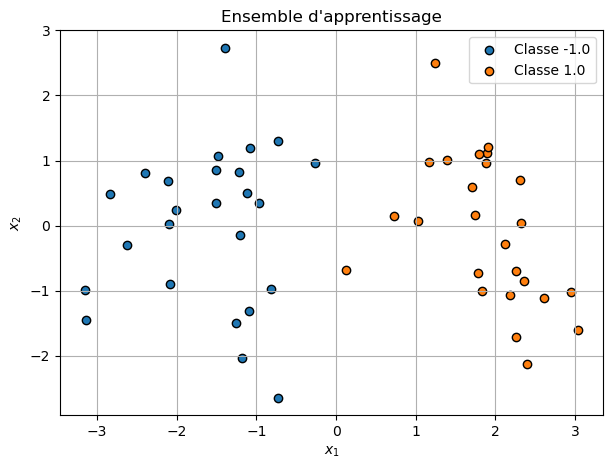

In [15]:
def affiche_classe(x, yd, titre="Ensemble d'apprentissage"):
    plt.figure(figsize=(7, 5))

    for classe in np.unique(yd):
        masque = yd == classe
        plt.scatter(
            x[0, masque],
            x[1, masque],
            label=f"Classe {classe}",
            edgecolors="black"
        )

    plt.xlabel("$x_1$")
    plt.ylabel("$x_2$")
    plt.title(titre)
    plt.legend()
    plt.grid(True)
    plt.show()


affiche_classe(x, yd)

### Entraînement du réseau

La fonction d’apprentissage utilise une sigmoïde en sortie. Si les étiquettes initiales sont \(-1\) et \(+1\), elles doivent être converties en \(0\) et \(1\) pour l’apprentissage. On conserve les étiquettes originales pour afficher et évaluer les classes.

In [16]:
classes = np.unique(yd)

if len(classes) != 2:
    raise ValueError("Cette fonction est prévue pour un problème à deux classes.")

# Conversion des étiquettes vers 0 et 1 pour la sigmoïde
if np.array_equal(classes, [-1, 1]):
    yd_train = (yd + 1) / 2
elif np.array_equal(classes, [0, 1]):
    yd_train = yd.copy()
else:
    yd_train = (yd == classes[1]).astype(float)

# Paramètres d'apprentissage
Epoch = 10
batch_size = 1  # apprentissage en ligne

# Entraînement
w1, w2, erreur = multiperceptron_widraw(
    x, yd_train, Epoch, batch_size
)

print("\nPoids finaux de la couche cachée :")
print(w1)

print("\nPoids finaux de la couche de sortie :")
print(w2)

Epoch 1/10, Erreur moyenne : 0.0287
Epoch 2/10, Erreur moyenne : 0.0204
Epoch 3/10, Erreur moyenne : 0.0160
Epoch 4/10, Erreur moyenne : 0.0127
Epoch 5/10, Erreur moyenne : 0.0102
Epoch 6/10, Erreur moyenne : 0.0083
Epoch 7/10, Erreur moyenne : 0.0069
Epoch 8/10, Erreur moyenne : 0.0058
Epoch 9/10, Erreur moyenne : 0.0050
Epoch 10/10, Erreur moyenne : 0.0043

Poids finaux de la couche cachée :
[[ 0.17676817 -0.25940078]
 [ 2.09156093  2.20945711]
 [-0.05559678 -0.09865914]]

Poids finaux de la couche de sortie :
[-2.16383921  2.15172035  2.70832586]


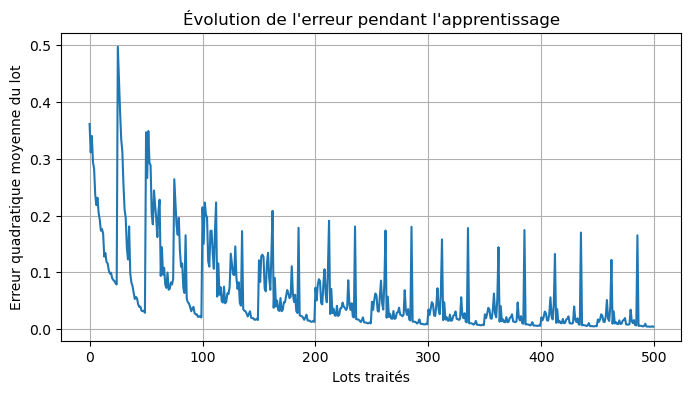

In [17]:
plt.figure(figsize=(8, 4))
plt.plot(erreur)
plt.xlabel("Lots traités")
plt.ylabel("Erreur quadratique moyenne du lot")
plt.title("Évolution de l'erreur pendant l'apprentissage")
plt.grid(True)
plt.show()

### Afficher les droites séparatrices des neurones cachés

Chaque neurone caché définit une droite dans le plan d’entrée lorsque son potentiel est nul :
$
w_{0}+w_{1}x_1+w_{2}x_2=0
$
On affiche ces deux droites avec les points de l’ensemble d’apprentissage.

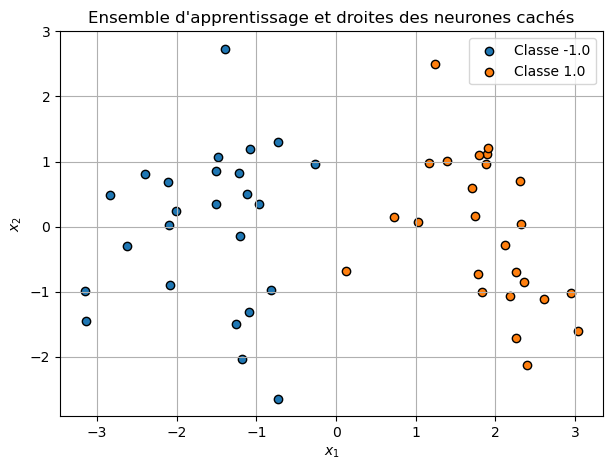

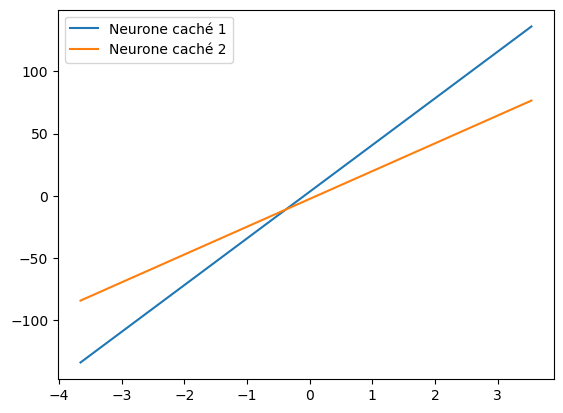

In [18]:
def afficher_droites_cachees(x, yd, w1):
    affiche_classe(x, yd, "Ensemble d'apprentissage et droites des neurones cachés")

    ax = plt.gca()
    t = np.linspace(x[0].min() - 0.5, x[0].max() + 0.5, 200)

    for j in range(2):
        poids = w1[:, j]

        # w[0] + w[1]*x1 + w[2]*x2 = 0
        if not np.isclose(poids[2], 0):
            z = -(poids[0] + poids[1] * t) / poids[2]
            ax.plot(t, z, label=f"Neurone caché {j + 1}")
        elif not np.isclose(poids[1], 0):
            x_vertical = -poids[0] / poids[1]
            ax.axvline(x_vertical, label=f"Neurone caché {j + 1}")

    ax.legend()
    plt.show()


afficher_droites_cachees(x, yd, w1)

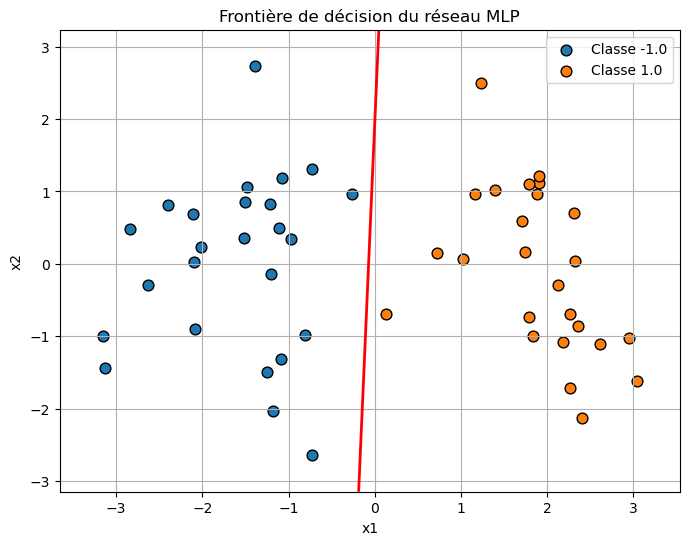

In [19]:

import numpy as np
import matplotlib.pyplot as plt

def afficher_frontiere_reseau(x, yd, w1, w2, resolution=200):
    # Vérifier les dimensions des données
    x = np.asarray(x)
    yd = np.asarray(yd).ravel()

    if x.ndim != 2 or x.shape[0] != 2:
        raise ValueError(f"x doit être de forme (2, N), forme reçue : {x.shape}")

    if x.shape[1] != len(yd):
        raise ValueError("Le nombre de points dans x doit correspondre à yd.")

    # Construire la grille couvrant les données
    marge = 0.5
    x1_min, x1_max = x[0, :].min() - marge, x[0, :].max() + marge
    x2_min, x2_max = x[1, :].min() - marge, x[1, :].max() + marge

    xx1, xx2 = np.meshgrid(
        np.linspace(x1_min, x1_max, resolution),
        np.linspace(x2_min, x2_max, resolution)
    )

    # Transformer la grille en matrice de forme (2, N)
    grille = np.vstack((xx1.ravel(), xx2.ravel()))

    # IMPORTANT : multiperceptron reçoit toute la matrice (2, N)
    sorties = np.asarray(
        multiperceptron(grille, w1, w2)
    ).reshape(xx1.shape)

    # Afficher les points d'apprentissage
    plt.figure(figsize=(8, 6))

    for classe in np.unique(yd):
        masque = (yd == classe)
        plt.scatter(
            x[0, masque], x[1, masque],
            label=f"Classe {classe}",
            edgecolors="black",
            s=60
        )

    # Tracer la frontière de décision du réseau
    plt.contour(
        xx1, xx2, sorties,
        levels=[0.5],
        colors="red",
        linewidths=2
    )

    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.title("Frontière de décision du réseau MLP")
    plt.legend()
    plt.grid(True)
    plt.show()


# Afficher la frontière du réseau entraîné
afficher_frontiere_reseau(x, yd, w1, w2)


### Conclusion de Partie I

Les résultats permettent d’évaluer la capacité du perceptron multicouche à apprendre les classes de l’ensemble d’apprentissage. La courbe d’erreur renseigne sur l’évolution de l’apprentissage, tandis que les droites des neurones cachés et la frontière finale permettent de visualiser la séparation des classes.

Le nombre de points mal classés permet de vérifier si le réseau a correctement appris les données. Si des erreurs subsistent, il faut notamment examiner le nombre d’époques, l’initialisation des poids et le taux d’apprentissage.

## Partie II : Réseaux denses et réseaux profonds

In [20]:

import numpy as np
import pandas as pd
from pathlib import Path

# Vérifier la présence du fichier Excel
fichier = Path("WangSignatures.xlsx")
if not fichier.exists():
    raise FileNotFoundError(
        "WangSignatures.xlsx est introuvable. "
        "Place-le dans le répertoire du notebook ou indique son chemin."
    )

# Noms exacts des onglets indiqués dans le TP
descripteurs = {
    "JCD": "WangSignaturesJCD",
    "PHOG": "WangSignaturesPHOG",
    "CEDD": "WangSignaturesCEDD",
    "FCTH": "WangSignaturesFCTH",
    "FuzzyColorHistogram": "WangSignaturesFuzzyColorHistogr"
}

X_descripteurs = {}
label = None

for nom, feuille in descripteurs.items():
    # La première colonne contient le nom de l'image
    df = pd.read_excel(
        fichier,
        sheet_name=feuille,
        header=None,
        index_col=0
    )

    # Construire les étiquettes à partir des noms de fichiers
    noms_images = df.index.astype(str)
    labels_feuille = np.array([
        int(nom_image.rsplit(".", 1)[0]) // 100
        for nom_image in noms_images
    ])

    # Vérifier que les onglets utilisent le même ordre d'images
    if label is None:
        label = labels_feuille
        noms_reference = noms_images.to_numpy()
    else:
        if not np.array_equal(noms_images.to_numpy(), noms_reference):
            raise ValueError(
                f"L'ordre des images diffère dans l'onglet {feuille}."
            )
        if not np.array_equal(labels_feuille, label):
            raise ValueError(
                f"Les étiquettes diffèrent dans l'onglet {feuille}."
            )

    # Extraire les caractéristiques numériques
    X = df.to_numpy(dtype=np.float32)

    if not np.isfinite(X).all():
        raise ValueError(
            f"Valeurs manquantes ou non finies dans l'onglet {feuille}."
        )

    X_descripteurs[nom] = X

# Afficher un bilan des données importées
print("Nombre d'images :", len(label))
print("Classes présentes :", np.unique(label))
print("Effectifs par classe :", np.bincount(label, minlength=10))
print("\nDimensions des descripteurs :")

for nom, X in X_descripteurs.items():
    print(f"{nom:22s} : {X.shape}")

print("\nPremières étiquettes :", label[:10])


Nombre d'images : 1000
Classes présentes : [0 1 2 3 4 5 6 7 8 9]
Effectifs par classe : [100 100 100 100 100 100 100 100 100 100]

Dimensions des descripteurs :
JCD                    : (1000, 168)
PHOG                   : (1000, 255)
CEDD                   : (1000, 144)
FCTH                   : (1000, 192)
FuzzyColorHistogram    : (1000, 125)

Premières étiquettes : [0 0 0 1 1 1 1 1 1 1]


### 2.1.2 Préparation des données d’apprentissage et de test

Nous séparons aléatoirement la base en `80 %` pour l’apprentissage et `20 %` pour le test, en conservant la proportion de chaque classe grâce à `stratify=label`. Les données de test simulent les images inconnues. La normalisation sera ajustée uniquement sur l’ensemble d’apprentissage.

In [21]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Une seule séparation commune à tous les descripteurs
indices = np.arange(len(label))

idx_train, idx_test = train_test_split(
    indices,
    test_size=0.20,
    random_state=42,
    stratify=label
)

y_train = label[idx_train]
y_test = label[idx_test]

print("Taille apprentissage :", len(idx_train))
print("Taille test :", len(idx_test))

print("\nRépartition des classes dans l'ensemble d'apprentissage :")
print(np.bincount(y_train, minlength=10))

print("\nRépartition des classes dans l'ensemble de test :")
print(np.bincount(y_test, minlength=10))


Taille apprentissage : 800
Taille test : 200

Répartition des classes dans l'ensemble d'apprentissage :
[80 80 80 80 80 80 80 80 80 80]

Répartition des classes dans l'ensemble de test :
[20 20 20 20 20 20 20 20 20 20]


### 2.1.2 Classification par perceptron multicouche (MLP)

Nous utilisons un réseau dense réalisé avec **Keras**. La couche de sortie possède `10 neurones` et utilise `softmax` pour produire une probabilité pour chacune des classes. La fonction de coût est `sparse_categorical_crossentropy`, adaptée aux étiquettes entières de 0 à 9.

In [22]:

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Fixer les graines aléatoires pour faciliter la reproductibilité
np.random.seed(42)
tf.random.set_seed(42)

def creer_mlp(nb_caracteristiques, neurones=128, dropout=0.3):
    model = keras.Sequential([
        keras.Input(shape=(nb_caracteristiques,)),
        layers.Dense(neurones, activation="relu"),
        layers.Dropout(dropout),
        layers.Dense(64, activation="relu"),
        layers.Dense(10, activation="softmax")
    ])

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


C:\Users\abdel\anaconda3\Lib\site-packages\keras\src\export\tf2onnx_lib.py:8: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "object"):


### Entraînement et évaluation avec un descripteur

Epoch 1/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.2922 - loss: 2.0742 - val_accuracy: 0.6125 - val_loss: 1.5239
Epoch 2/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6313 - loss: 1.2980 - val_accuracy: 0.6938 - val_loss: 1.1176
Epoch 3/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7672 - loss: 0.8869 - val_accuracy: 0.7437 - val_loss: 0.8792
Epoch 4/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8141 - loss: 0.6621 - val_accuracy: 0.8000 - val_loss: 0.7445
Epoch 5/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8297 - loss: 0.5444 - val_accuracy: 0.8062 - val_loss: 0.6811
Epoch 6/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8500 - loss: 0.4597 - val_accuracy: 0.8062 - val_loss: 0.6454
Epoch 7/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8875 - loss: 0.3857 - val_accuracy: 0.8125 - val_loss: 0.6068
Epoch 8/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9062 - loss: 0.3275 - val_accuracy: 0.7937 - val_loss

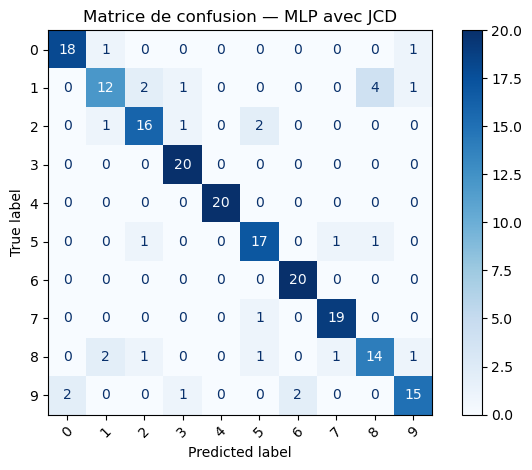

In [23]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    confusion_matrix
)
import matplotlib.pyplot as plt

# Standardisation sans fuite d'information
scaler_jcd = StandardScaler()

X_train_jcd = scaler_jcd.fit_transform(
    X_descripteurs["JCD"][idx_train]
)
X_test_jcd = scaler_jcd.transform(
    X_descripteurs["JCD"][idx_test]
)

# Création et entraînement du modèle
model_jcd = creer_mlp(X_train_jcd.shape[1])

historique_jcd = model_jcd.fit(
    X_train_jcd,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=7,
            restore_best_weights=True
        )
    ],
    verbose=1
)

# Évaluation sur les données de test
loss_jcd, accuracy_jcd = model_jcd.evaluate(
    X_test_jcd, y_test, verbose=0
)

probabilites_jcd = model_jcd.predict(X_test_jcd, verbose=0)
y_pred_jcd = np.argmax(probabilites_jcd, axis=1)

print(f"Précision sur le test : {accuracy_jcd:.4f}")
print(f"Taux d'erreur : {1 - accuracy_jcd:.4f}")

print("\nRapport de classification :")
print(classification_report(y_test, y_pred_jcd, zero_division=0))

ConfusionMatrixDisplay(
    confusion_matrix(y_test, y_pred_jcd),
    display_labels=np.arange(10)
).plot(cmap="Blues", xticks_rotation=45)

plt.title("Matrice de confusion — MLP avec JCD")
plt.tight_layout()
plt.show()


### Évolution de l’apprentissage

Nous observons l’évolution de la précision et de la fonction de coût pour les données d’apprentissage et de validation. Un écart croissant entre ces courbes peut indiquer un surapprentissage.

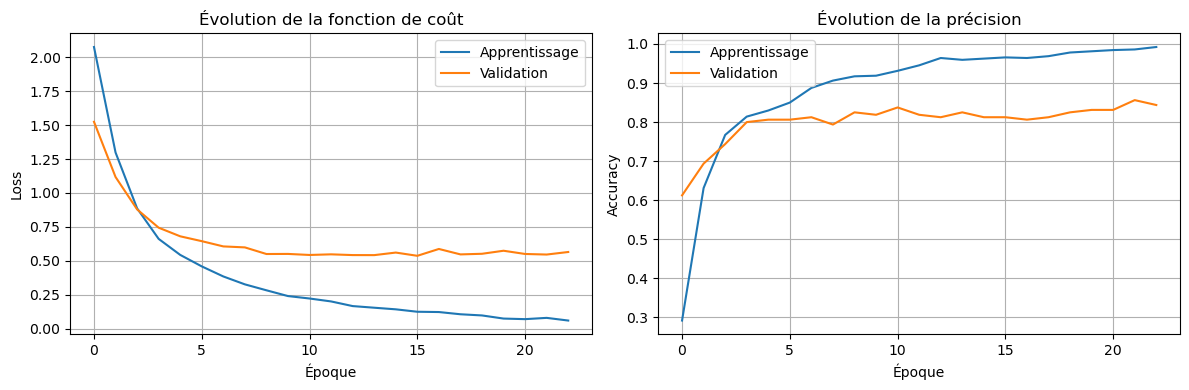

In [24]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(historique_jcd.history["loss"], label="Apprentissage")
axes[0].plot(historique_jcd.history["val_loss"], label="Validation")
axes[0].set_title("Évolution de la fonction de coût")
axes[0].set_xlabel("Époque")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(historique_jcd.history["accuracy"], label="Apprentissage")
axes[1].plot(historique_jcd.history["val_accuracy"], label="Validation")
axes[1].set_title("Évolution de la précision")
axes[1].set_xlabel("Époque")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


### Tester les cinq descripteurs et leur concaténation

Nous répétons la même expérience pour chaque descripteur, avec la même séparation apprentissage/test. Nous comparons les précisions sur le test et les taux d’erreur.


--- Descripteur : JCD ---
Accuracy test : 0.8000
Taux d'erreur : 0.2000


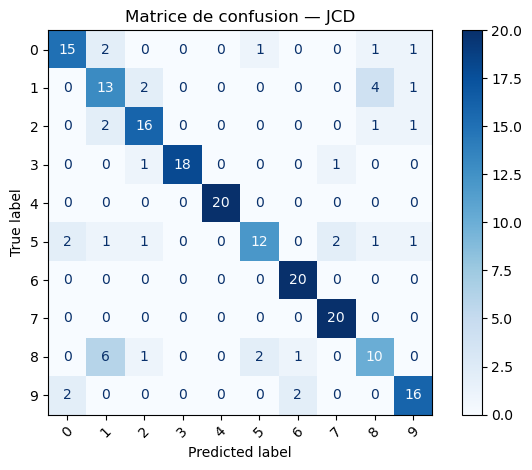


--- Descripteur : PHOG ---
Accuracy test : 0.5850
Taux d'erreur : 0.4150


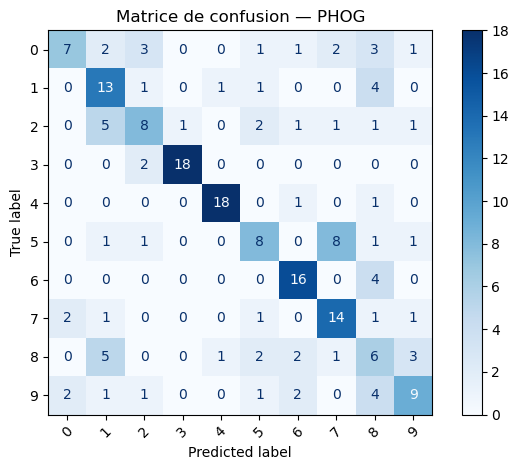


--- Descripteur : CEDD ---
Accuracy test : 0.8050
Taux d'erreur : 0.1950


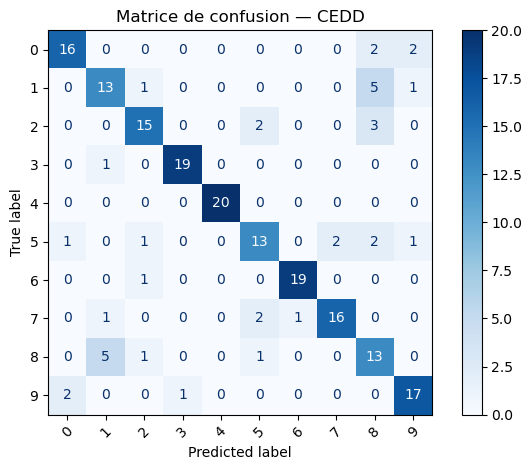


--- Descripteur : FCTH ---
Accuracy test : 0.7200
Taux d'erreur : 0.2800


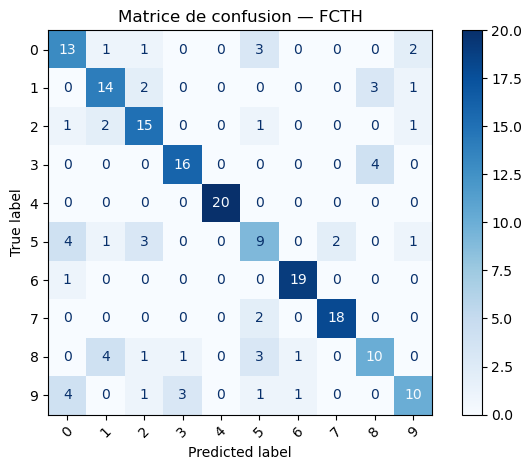


--- Descripteur : FuzzyColorHistogram ---
Accuracy test : 0.7550
Taux d'erreur : 0.2450


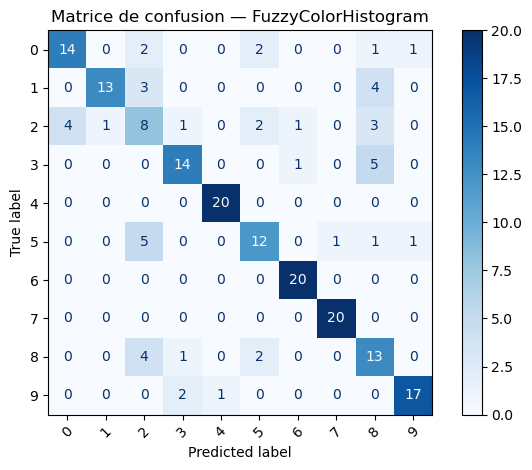


--- Descripteur : Concaténation ---
Accuracy test : 0.8250
Taux d'erreur : 0.1750


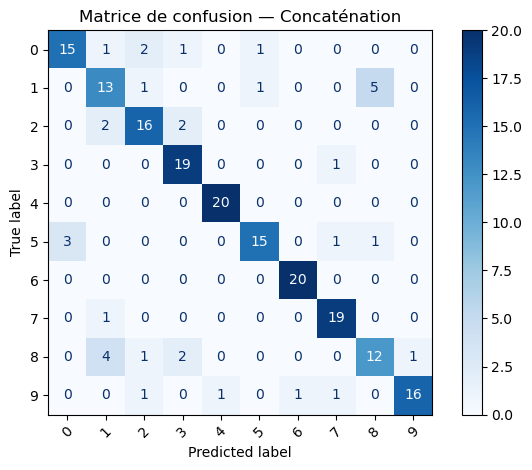

,Descripteur,Accuracy test,Taux d'erreur
5,Concaténation,0.825,0.175
2,CEDD,0.805,0.195
0,JCD,0.800,0.200
4,FuzzyColorHistogram,0.755,0.245
3,FCTH,0.720,0.280
1,PHOG,0.585,0.415


In [25]:

# Préparer les données : chaque descripteur est normalisé séparément.
X_train_descripteurs = {}
X_test_descripteurs = {}

for nom, X in X_descripteurs.items():
    scaler = StandardScaler()

    X_train_descripteurs[nom] = scaler.fit_transform(X[idx_train])
    X_test_descripteurs[nom] = scaler.transform(X[idx_test])

# Concaténer les descripteurs normalisés
X_train_descripteurs["Concaténation"] = np.concatenate(
    [X_train_descripteurs[nom] for nom in descripteurs],
    axis=1
)

X_test_descripteurs["Concaténation"] = np.concatenate(
    [X_test_descripteurs[nom] for nom in descripteurs],
    axis=1
)

# Entraîner et évaluer un MLP par représentation
resultats_mlp = []
modeles_mlp = {}
historiques_mlp = {}

for nom, Xtr in X_train_descripteurs.items():
    print(f"\n--- Descripteur : {nom} ---")

    Xte = X_test_descripteurs[nom]
    model = creer_mlp(Xtr.shape[1])

    historique = model.fit(
        Xtr,
        y_train,
        epochs=50,
        batch_size=32,
        validation_split=0.2,
        callbacks=[
            keras.callbacks.EarlyStopping(
                monitor="val_loss",
                patience=7,
                restore_best_weights=True
            )
        ],
        verbose=0
    )

    loss, accuracy = model.evaluate(Xte, y_test, verbose=0)
    predictions = np.argmax(model.predict(Xte, verbose=0), axis=1)

    resultats_mlp.append({
        "Descripteur": nom,
        "Accuracy test": accuracy,
        "Taux d'erreur": 1 - accuracy
    })

    modeles_mlp[nom] = model
    historiques_mlp[nom] = historique

    print(f"Accuracy test : {accuracy:.4f}")
    print(f"Taux d'erreur : {1 - accuracy:.4f}")

    ConfusionMatrixDisplay(
        confusion_matrix(y_test, predictions),
        display_labels=np.arange(10)
    ).plot(cmap="Blues", xticks_rotation=45)

    plt.title(f"Matrice de confusion — {nom}")
    plt.tight_layout()
    plt.show()

tableau_mlp = pd.DataFrame(resultats_mlp)
display(tableau_mlp.sort_values("Accuracy test", ascending=False))


### Comparer avec les k plus proches voisins (KppV)

On comparer le **MLP** à un classifieur KppV, en optimisant le nombre de voisins **\(k\)** et la distance par validation croisée. Nous utilisons une recherche par `validation croisée` sur les données d’apprentissage uniquement, puis évaluons le meilleur modèle sur le test.

In [26]:

from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

parametres_knn = {
    "knn__n_neighbors": [1, 3, 5, 7, 9, 11, 15],
    "knn__metric": ["euclidean", "manhattan"]
}

resultats_knn = []
modeles_knn = {}

for nom, Xtr in X_train_descripteurs.items():
    print(f"\n--- KppV : {nom} ---")

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier())
    ])

    recherche = GridSearchCV(
        pipeline,
        param_grid=parametres_knn,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )

    recherche.fit(
        X_descripteurs[nom][idx_train]
        if nom != "Concaténation"
        else np.concatenate(
            [X_descripteurs[d][idx_train] for d in descripteurs],
            axis=1
        ),
        y_train
    )

    # Évaluer le meilleur modèle sur les données de test correspondantes
    Xte_brut = (
        X_descripteurs[nom][idx_test]
        if nom != "Concaténation"
        else np.concatenate(
            [X_descripteurs[d][idx_test] for d in descripteurs],
            axis=1
        )
    )

    y_pred = recherche.predict(Xte_brut)
    accuracy = accuracy_score(y_test, y_pred)

    modeles_knn[nom] = recherche.best_estimator_

    resultats_knn.append({
        "Descripteur": nom,
        "Meilleurs paramètres": recherche.best_params_,
        "Accuracy CV": recherche.best_score_,
        "Accuracy test": accuracy,
        "Taux d'erreur": 1 - accuracy
    })

    print("Meilleurs paramètres :", recherche.best_params_)
    print(f"Accuracy validation croisée : {recherche.best_score_:.4f}")
    print(f"Accuracy test : {accuracy:.4f}")

tableau_knn = pd.DataFrame(resultats_knn)
display(tableau_knn.sort_values("Accuracy test", ascending=False))



--- KppV : JCD ---


C:\Users\abdel\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\abdel\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\abdel\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\abdel\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^

Meilleurs paramètres : {'knn__metric': 'euclidean', 'knn__n_neighbors': 7}
Accuracy validation croisée : 0.7750
Accuracy test : 0.7500

--- KppV : PHOG ---
Meilleurs paramètres : {'knn__metric': 'manhattan', 'knn__n_neighbors': 1}
Accuracy validation croisée : 0.5700
Accuracy test : 0.5100

--- KppV : CEDD ---
Meilleurs paramètres : {'knn__metric': 'euclidean', 'knn__n_neighbors': 5}
Accuracy validation croisée : 0.7638
Accuracy test : 0.7750

--- KppV : FCTH ---
Meilleurs paramètres : {'knn__metric': 'manhattan', 'knn__n_neighbors': 5}
Accuracy validation croisée : 0.7537
Accuracy test : 0.7350

--- KppV : FuzzyColorHistogram ---
Meilleurs paramètres : {'knn__metric': 'euclidean', 'knn__n_neighbors': 1}
Accuracy validation croisée : 0.6613
Accuracy test : 0.6300

--- KppV : Concaténation ---
Meilleurs paramètres : {'knn__metric': 'manhattan', 'knn__n_neighbors': 11}
Accuracy validation croisée : 0.8287
Accuracy test : 0.8150


,Descripteur,Meilleurs paramètres,Accuracy CV,Accuracy test,Taux d'erreur
5,Concaténation,"{'knn__metric': 'manhattan', 'knn__n_neighbors...",0.82875,0.815,0.185
2,CEDD,"{'knn__metric': 'euclidean', 'knn__n_neighbors...",0.76375,0.775,0.225
0,JCD,"{'knn__metric': 'euclidean', 'knn__n_neighbors...",0.77500,0.750,0.250
3,FCTH,"{'knn__metric': 'manhattan', 'knn__n_neighbors...",0.75375,0.735,0.265
4,FuzzyColorHistogram,"{'knn__metric': 'euclidean', 'knn__n_neighbors...",0.66125,0.630,0.370
1,PHOG,"{'knn__metric': 'manhattan', 'knn__n_neighbors...",0.57000,0.510,0.490


,Descripteur,Accuracy MLP,Taux d'erreur,Accuracy KppV
0,JCD,0.800,0.200,0.750
1,PHOG,0.585,0.415,0.510
2,CEDD,0.805,0.195,0.775
3,FCTH,0.720,0.280,0.735
4,FuzzyColorHistogram,0.755,0.245,0.630
5,Concaténation,0.825,0.175,0.815


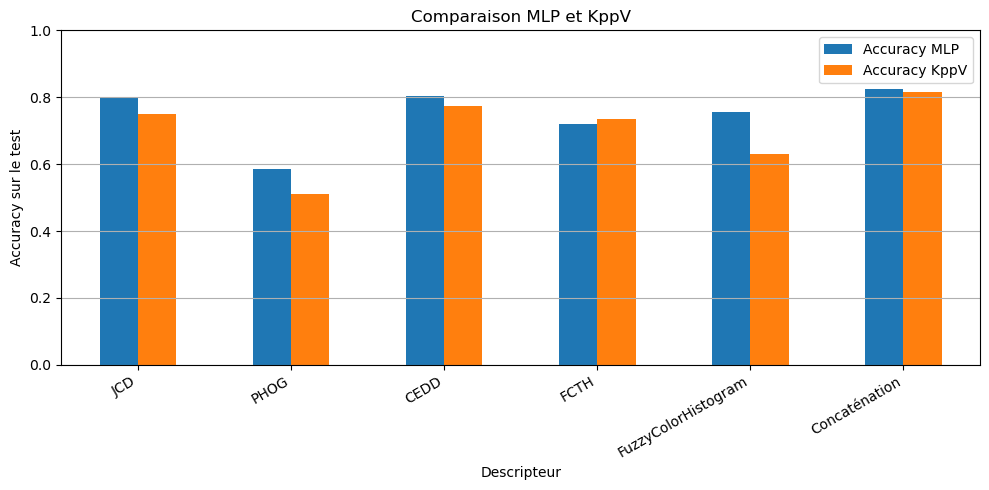

In [27]:

comparaison = tableau_mlp.merge(
    tableau_knn[["Descripteur", "Accuracy test"]],
    on="Descripteur",
    suffixes=("_MLP", "_KppV")
)

comparaison = comparaison.rename(columns={
    "Accuracy test_MLP": "Accuracy MLP",
    "Accuracy test_KppV": "Accuracy KppV"
})

display(comparaison)

comparaison.plot(
    x="Descripteur",
    y=["Accuracy MLP", "Accuracy KppV"],
    kind="bar",
    figsize=(10, 5)
)

plt.ylabel("Accuracy sur le test")
plt.ylim(0, 1)
plt.title("Comparaison MLP et KppV")
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y")
plt.tight_layout()
plt.show()


## 2.2 Approche profonde : apprentissage des descripteurs

Nous chargeons les images de la base `Wang` à partir de leurs noms (0.jpg à 999.jpg). Chaque image est redimensionnée à une taille commune, et sa classe est calculée à partir de son numéro. Les pixels sont normalisés entre `0` et `1`.

In [28]:

from pathlib import Path
from PIL import Image

from sklearn.model_selection import train_test_split

dossier_images = Path("Wang")
taille_image = (128, 128)  # Possibilité de passer à (256, 256)

images = []
labels_images = []

for i in range(1000):
    chemin = dossier_images / f"{i}.jpg"

    if not chemin.exists():
        raise FileNotFoundError(f"Image introuvable : {chemin}")

    with Image.open(chemin) as img:
        img = img.convert("RGB")
        img = img.resize(taille_image)
        images.append(np.asarray(img, dtype=np.float32))

    labels_images.append(i // 100)

X_images = np.array(images, dtype=np.float32) / 255.0
y_images = np.array(labels_images, dtype=np.int64)

idx_img_train, idx_img_test = train_test_split(
    np.arange(len(y_images)),
    test_size=0.20,
    random_state=42,
    stratify=y_images
)

X_img_train = X_images[idx_img_train]
X_img_test = X_images[idx_img_test]
y_img_train = y_images[idx_img_train]
y_img_test = y_images[idx_img_test]

print("Dimensions des images :", X_images.shape)
print("Images d'apprentissage :", X_img_train.shape[0])
print("Images de test :", X_img_test.shape[0])
print("Répartition des classes :", np.bincount(y_images))


Dimensions des images : (1000, 128, 128, 3)
Images d'apprentissage : 800
Images de test : 200
Répartition des classes : [100 100 100 100 100 100 100 100 100 100]


### Construction d’un premier réseau convolutif (CNN)

Nous construisons une architecture simple composée de couches convolutives pour extraire les caractéristiques, de couches de sous-échantillonnage pour réduire les dimensions, puis de couches denses pour classifier les images en dix classes. Cette première architecture sert de référence avant les améliorations.

In [29]:

def creer_cnn():
    model = keras.Sequential([
        keras.Input(shape=(taille_image[1], taille_image[0], 3)),

        layers.Conv2D(32, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.4),
        layers.Dense(10, activation="softmax")
    ])

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


cnn = creer_cnn()
cnn.summary()


Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 126, 126, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 63, 63, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 61, 61, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 30, 30, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 57600)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_21 (Dense)                     │ (None, 128)                 │       7,372,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_7 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_22 (Dense)                     │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 7,393,610 (28.20 MB)

 Trainable params: 7,393,610 (28.20 MB)

 Non-trainable params: 0 (0.00 B)

### Entraînement et évaluation du CNN

Nous entraînons le réseau avec une partie des données d’apprentissage réservée à la validation. L’arrêt anticipé permet de limiter le surapprentissage. Nous évaluons ensuite le modèle sur les images de test, qui n’ont pas été utilisées pour l’entraînement.

Epoch 1/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 192ms/step - accuracy: 0.1750 - loss: 2.9684 - val_accuracy: 0.3500 - val_loss: 1.9743
Epoch 2/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 171ms/step - accuracy: 0.4344 - loss: 1.6426 - val_accuracy: 0.6687 - val_loss: 1.3520
Epoch 3/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 150ms/step - accuracy: 0.5547 - loss: 1.2459 - val_accuracy: 0.7063 - val_loss: 1.0393
Epoch 4/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 152ms/step - accuracy: 0.6797 - loss: 0.9624 - val_accuracy: 0.6438 - val_loss: 1.0261
Epoch 5/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 180ms/step - accuracy: 0.7609 - loss: 0.7481 - val_accuracy: 0.6875 - val_loss: 0.9746
Epoch 6/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 154ms/step - accuracy: 0.7844 - loss: 0.6329 - val_accuracy: 0.7000 - val_loss: 0.7618
Epoch 7/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 144ms/step - accuracy: 0.8172 - loss: 0.5504 - val_accuracy: 0.7250 - val_loss: 0.7739
Epoch 8/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 151ms/step - accuracy: 0.8641 - loss: 0.4015 - val_accuracy: 0.

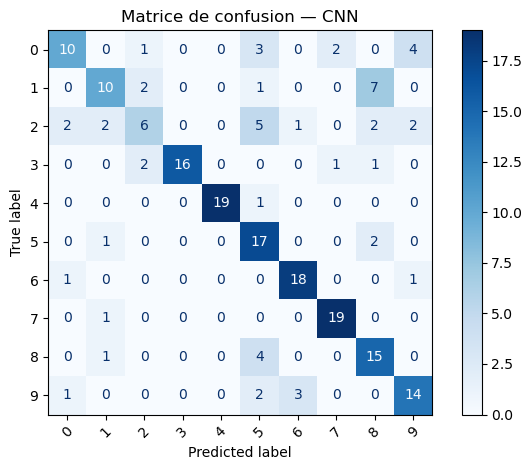

In [30]:

historique_cnn = cnn.fit(
    X_img_train,
    y_img_train,
    epochs=20,
    batch_size=32,
    validation_split=0.2,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=4,
            restore_best_weights=True
        )
    ],
    verbose=1
)

loss_cnn, accuracy_cnn = cnn.evaluate(
    X_img_test, y_img_test, verbose=0
)

probabilites_cnn = cnn.predict(X_img_test, verbose=0)
y_pred_cnn = np.argmax(probabilites_cnn, axis=1)

print(f"Loss sur le test : {loss_cnn:.4f}")
print(f"Accuracy sur le test : {accuracy_cnn:.4f}")
print(f"Taux d'erreur : {1 - accuracy_cnn:.4f}")

print("\nRapport de classification :")
print(classification_report(
    y_img_test, y_pred_cnn, zero_division=0
))

ConfusionMatrixDisplay(
    confusion_matrix(y_img_test, y_pred_cnn),
    display_labels=np.arange(10)
).plot(cmap="Blues", xticks_rotation=45)

plt.title("Matrice de confusion — CNN")
plt.tight_layout()
plt.show()


### Analyse des courbes d’apprentissage

Nous comparons la fonction de coût et la précision sur les ensembles d’apprentissage et de validation. Une précision d’apprentissage élevée accompagnée d’une précision de validation plus faible peut révéler du surapprentissage.

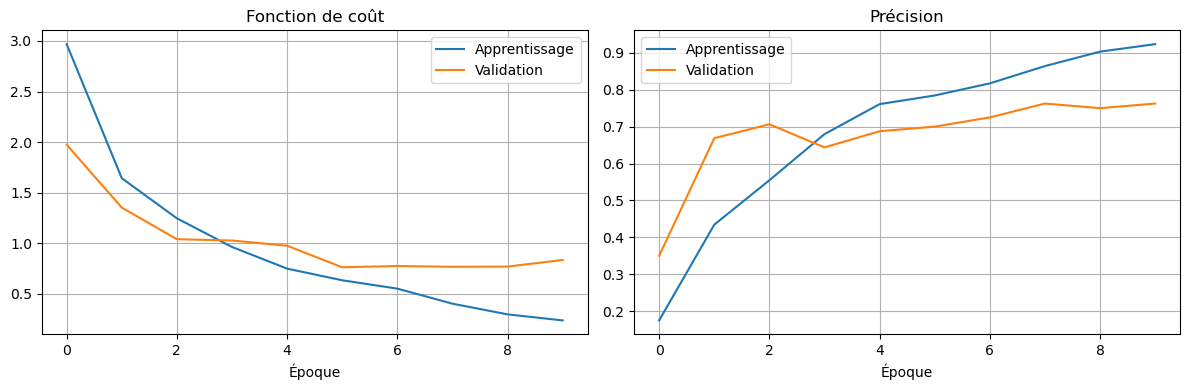

In [31]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(historique_cnn.history["loss"], label="Apprentissage")
axes[0].plot(historique_cnn.history["val_loss"], label="Validation")
axes[0].set_title("Fonction de coût")
axes[0].set_xlabel("Époque")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(historique_cnn.history["accuracy"], label="Apprentissage")
axes[1].plot(historique_cnn.history["val_accuracy"], label="Validation")
axes[1].set_title("Précision")
axes[1].set_xlabel("Époque")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


### Comparaison des approches

Nous comparons les performances obtenues avec le meilleur MLP fondé sur les descripteurs et avec le CNN qui apprend directement à partir des images.

,Approche,Accuracy test,Taux d'erreur
0,MLP — Concaténation,0.825,0.175
1,CNN,0.720,0.280


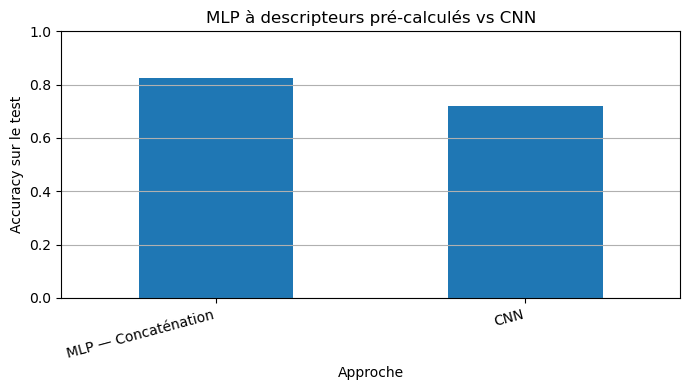

In [32]:

meilleur_mlp = tableau_mlp.loc[
    tableau_mlp["Accuracy test"].idxmax()
]

comparaison_finale = pd.DataFrame([
    {
        "Approche": f"MLP — {meilleur_mlp['Descripteur']}",
        "Accuracy test": meilleur_mlp["Accuracy test"],
        "Taux d'erreur": meilleur_mlp["Taux d'erreur"]
    },
    {
        "Approche": "CNN",
        "Accuracy test": accuracy_cnn,
        "Taux d'erreur": 1 - accuracy_cnn
    }
])

display(comparaison_finale)

comparaison_finale.plot(
    x="Approche",
    y="Accuracy test",
    kind="bar",
    legend=False,
    figsize=(7, 4)
)

plt.ylabel("Accuracy sur le test")
plt.ylim(0, 1)
plt.title("MLP à descripteurs pré-calculés vs CNN")
plt.xticks(rotation=15, ha="right")
plt.grid(axis="y")
plt.tight_layout()
plt.show()


### Transfert d’apprentissage avec VGG16

Nous utilisons VGG16 comme extracteur de caractéristiques, puis ajoutons une tête de classification adaptée aux dix classes de Wang. Cette méthode réutilise des caractéristiques apprises sur une grande base d’images.

In [33]:

from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input

# VGG16 attend des images de taille compatible avec son entrée
taille_vgg = (224, 224)

def preparer_vgg(X):
    X_resize = tf.image.resize(X, taille_vgg).numpy()
    X_resize = X_resize * 255.0
    return preprocess_input(X_resize)

X_vgg_train = preparer_vgg(X_img_train)
X_vgg_test = preparer_vgg(X_img_test)

base_vgg = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Geler les poids pré-entraînés pour commencer
base_vgg.trainable = False

entree = keras.Input(shape=(224, 224, 3))
caracteristiques = base_vgg(entree, training=False)
caracteristiques = layers.GlobalAveragePooling2D()(caracteristiques)
caracteristiques = layers.Dense(128, activation="relu")(caracteristiques)
caracteristiques = layers.Dropout(0.4)(caracteristiques)
sortie = layers.Dense(10, activation="softmax")(caracteristiques)

model_vgg = keras.Model(entree, sortie)

model_vgg.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_vgg.summary()


Model: "functional_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_9 (InputLayer)           │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ vgg16 (Functional)                   │ (None, 7, 7, 512)           │      14,714,688 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 512)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_23 (Dense)                     │ (None, 128)                 │          65,664 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_8 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_24 (Dense)                     │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 14,781,642 (56.39 MB)

 Trainable params: 66,954 (261.54 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

### Entraînement et évaluation

Epoch 1/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 62s 2s/step - accuracy: 0.6062 - loss: 2.0291 - val_accuracy: 0.9125 - val_loss: 0.2358
Epoch 2/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 65s 2s/step - accuracy: 0.8969 - loss: 0.3142 - val_accuracy: 0.9438 - val_loss: 0.1280
Epoch 3/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 69s 2s/step - accuracy: 0.9516 - loss: 0.1379 - val_accuracy: 0.9438 - val_loss: 0.1432
Epoch 4/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 71s 2s/step - accuracy: 0.9609 - loss: 0.0880 - val_accuracy: 0.9375 - val_loss: 0.1548
Epoch 5/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 67s 2s/step - accuracy: 0.9828 - loss: 0.0624 - val_accuracy: 0.9438 - val_loss: 0.1692
Accuracy VGG16 sur le test : 0.9500
Taux d'erreur : 0.0500


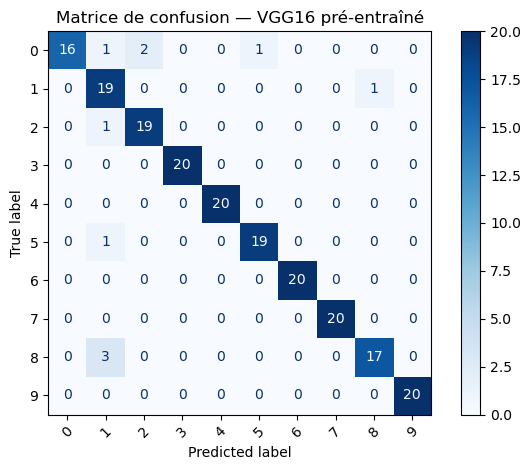

In [34]:

historique_vgg = model_vgg.fit(
    X_vgg_train,
    y_img_train,
    epochs=10,
    batch_size=16,
    validation_split=0.2,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True
        )
    ],
    verbose=1
)

loss_vgg, accuracy_vgg = model_vgg.evaluate(
    X_vgg_test, y_img_test, verbose=0
)

y_pred_vgg = np.argmax(
    model_vgg.predict(X_vgg_test, verbose=0),
    axis=1
)

print(f"Accuracy VGG16 sur le test : {accuracy_vgg:.4f}")
print(f"Taux d'erreur : {1 - accuracy_vgg:.4f}")

ConfusionMatrixDisplay(
    confusion_matrix(y_img_test, y_pred_vgg),
    display_labels=np.arange(10)
).plot(cmap="Blues", xticks_rotation=45)

plt.title("Matrice de confusion — VGG16 pré-entraîné")
plt.tight_layout()
plt.show()


### Entraînement de ResNet50 et EfficientNetB0

Nous utilisons les poids pré-entraînés sur `ImageNet`, gelons les couches convolutives et ajoutons une tête de classification à dix classes. Les deux modèles sont entraînés sur le même ensemble d’apprentissage et évalués sur le même ensemble de test.

In [35]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import ResNet50, EfficientNetB0
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)
import time
import gc

TAILLE_MODELE = (224, 224)

# Les données images doivent déjà être normalisées entre 0 et 1.
def preparer_images_transfer(X, nom_modele):
    X_resize = tf.image.resize(X, TAILLE_MODELE).numpy()
    X_resize = X_resize * 255.0

    if nom_modele == "ResNet50":
        return resnet_preprocess(X_resize)

    elif nom_modele == "EfficientNetB0":
        # EfficientNetB0 intègre le prétraitement des pixels dans le modèle.
        return X_resize

    else:
        raise ValueError("Modèle non pris en charge")


def creer_modele_transfer(constructeur):
    base = constructeur(
        weights="imagenet",
        include_top=False,
        input_shape=(224, 224, 3),
        pooling="avg"
    )
    base.trainable = False

    entree = keras.Input(shape=(224, 224, 3))
    caracteristiques = base(entree, training=False)
    x = layers.Dense(128, activation="relu")(caracteristiques)
    x = layers.Dropout(0.3)(x)
    sortie = layers.Dense(10, activation="softmax")(x)

    model = keras.Model(entree, sortie)
    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model



Entraînement de ResNet50

Epoch 1/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 37s 794ms/step - accuracy: 0.8250 - loss: 0.5555 - val_accuracy: 0.9750 - val_loss: 0.0704
Epoch 2/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 26s 651ms/step - accuracy: 0.9859 - loss: 0.0497 - val_accuracy: 0.9563 - val_loss: 0.0842
Epoch 3/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 26s 665ms/step - accuracy: 0.9953 - loss: 0.0182 - val_accuracy: 0.9688 - val_loss: 0.0911
Epoch 4/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 27s 669ms/step - accuracy: 1.0000 - loss: 0.0104 - val_accuracy: 0.9812 - val_loss: 0.1029

Accuracy : 0.9650
Taux d'erreur : 0.0350
Temps d'entraînement : 116.0 secondes
              precision    recall  f1-score   support

           0       0.95      0.95      0.95        20
           1       0.83      0.95      0.88        20
           2       1.00      0.90      0.95        20
           3       1.00      1.00      1.00        20
           4       1.00      1.00      1.00        20
           5       1.00      1.00      1.00        2

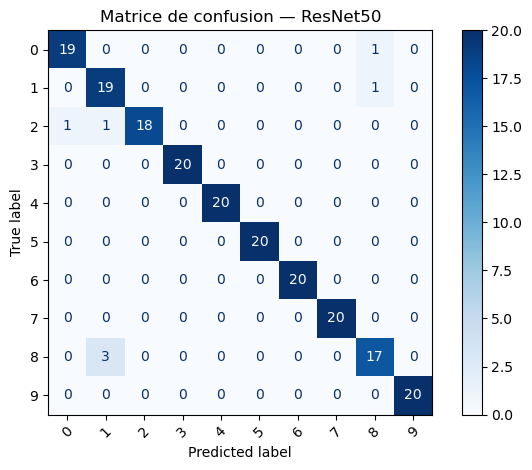


Entraînement de EfficientNetB0
Epoch 1/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 20s 327ms/step - accuracy: 0.8547 - loss: 0.6186 - val_accuracy: 0.9875 - val_loss: 0.0952
Epoch 2/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 11s 286ms/step - accuracy: 0.9922 - loss: 0.0434 - val_accuracy: 0.9875 - val_loss: 0.0705
Epoch 3/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 11s 286ms/step - accuracy: 0.9953 - loss: 0.0273 - val_accuracy: 0.9875 - val_loss: 0.0674
Epoch 4/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 12s 295ms/step - accuracy: 0.9984 - loss: 0.0136 - val_accuracy: 0.9875 - val_loss: 0.0670
Epoch 5/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 12s 306ms/step - accuracy: 0.9984 - loss: 0.0105 - val_accuracy: 0.9812 - val_loss: 0.0701
Epoch 6/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 12s 302ms/step - accuracy: 1.0000 - loss: 0.0069 - val_accuracy: 0.9812 - val_loss: 0.0692
Epoch 7/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 12s 296ms/step - accuracy: 1.0000 - loss: 0.0053 - val_accuracy: 0.9812 - val_loss: 0.0733

Accuracy : 0.9650
Taux d'erreur : 0.0350
Temps d'entraînement : 

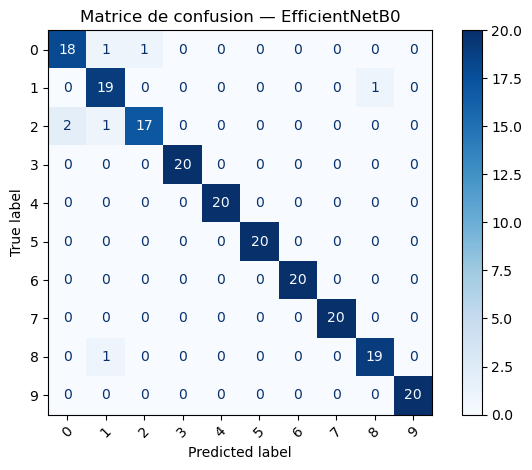

In [36]:

constructeurs = {
    "ResNet50": ResNet50,
    "EfficientNetB0": EfficientNetB0
}

resultats_nouveaux = []
modeles_nouveaux = {}
historiques_nouveaux = {}
predictions_nouveaux = {}

for nom, constructeur in constructeurs.items():
    print(f"\n{'=' * 45}\nEntraînement de {nom}\n{'=' * 45}")

    tf.keras.backend.clear_session()
    gc.collect()

    Xtr = preparer_images_transfer(X_img_train, nom)
    Xte = preparer_images_transfer(X_img_test, nom)

    model = creer_modele_transfer(constructeur)

    debut = time.time()

    historique = model.fit(
        Xtr,
        y_img_train,
        epochs=10,
        batch_size=16,
        validation_split=0.2,
        callbacks=[
            keras.callbacks.EarlyStopping(
                monitor="val_loss",
                patience=3,
                restore_best_weights=True
            )
        ],
        verbose=1
    )

    temps = time.time() - debut

    probabilites = model.predict(Xte, verbose=0)
    y_pred = np.argmax(probabilites, axis=1)

    accuracy = accuracy_score(y_img_test, y_pred)

    resultats_nouveaux.append({
        "Modèle": nom,
        "Accuracy test": accuracy,
        "Taux d'erreur": 1 - accuracy,
        "Temps entraînement (s)": temps,
        "Époques effectuées": len(historique.history["loss"])
    })

    modeles_nouveaux[nom] = model
    historiques_nouveaux[nom] = historique
    predictions_nouveaux[nom] = y_pred

    print(f"\nAccuracy : {accuracy:.4f}")
    print(f"Taux d'erreur : {1 - accuracy:.4f}")
    print(f"Temps d'entraînement : {temps:.1f} secondes")
    print(classification_report(
        y_img_test, y_pred, zero_division=0
    ))

    matrice = confusion_matrix(
        y_img_test, y_pred, labels=np.arange(10)
    )

    ConfusionMatrixDisplay(
        confusion_matrix=matrice,
        display_labels=np.arange(10)
    ).plot(cmap="Blues", xticks_rotation=45)

    plt.title(f"Matrice de confusion — {nom}")
    plt.tight_layout()
    plt.show()

    del Xtr, Xte


### Comparaison entre VGG16, ResNet50 et EfficientNetB0

Nous comparons les trois réseaux pré-entraînés à partir de leur précision sur le même ensemble de test.

,Modèle,Accuracy test,Taux d'erreur
0,ResNet50,0.965,0.035
1,EfficientNetB0,0.965,0.035
2,VGG16,0.950,0.050


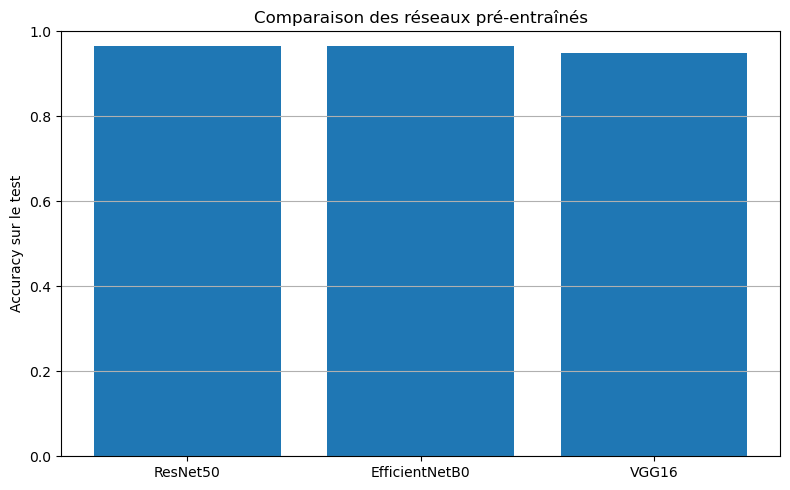

Meilleur réseau : ResNet50
Accuracy : 0.9650
Taux d'erreur : 0.0350


In [37]:

# Réutiliser le résultat VGG16 déjà calculé
resultats_reseaux = [
    {
        "Modèle": "VGG16",
        "Accuracy test": float(accuracy_vgg),
        "Taux d'erreur": 1 - float(accuracy_vgg)
    }
]

# Ajouter ResNet50 et EfficientNetB0
for resultat in resultats_nouveaux:
    resultats_reseaux.append({
        "Modèle": resultat["Modèle"],
        "Accuracy test": resultat["Accuracy test"],
        "Taux d'erreur": resultat["Taux d'erreur"]
    })

# Créer et trier le tableau comparatif
tableau_reseaux = pd.DataFrame(resultats_reseaux)
tableau_reseaux = tableau_reseaux.sort_values(
    "Accuracy test", ascending=False
).reset_index(drop=True)

display(tableau_reseaux)

# Comparaison graphique
plt.figure(figsize=(8, 5))
plt.bar(
    tableau_reseaux["Modèle"],
    tableau_reseaux["Accuracy test"]
)
plt.ylim(0, 1)
plt.ylabel("Accuracy sur le test")
plt.title("Comparaison des réseaux pré-entraînés")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

# Identifier le meilleur réseau
meilleur_reseau = tableau_reseaux.iloc[0]

print("Meilleur réseau :", meilleur_reseau["Modèle"])
print(f"Accuracy : {meilleur_reseau['Accuracy test']:.4f}")
print(f"Taux d'erreur : {meilleur_reseau["Taux d'erreur"]:.4f}")


### 3. Comparaison globale de toutes les approches

,Modèle,Accuracy test,Approche,Taux d'erreur
0,EfficientNetB0,0.965,Transfert d'apprentissage,0.035
1,ResNet50,0.965,Transfert d'apprentissage,0.035
2,VGG16,0.950,Transfert d'apprentissage,0.050
3,MLP — Concaténation,0.825,MLP — descripteurs,0.175
4,KppV — Concaténation,0.815,KppV — descripteurs,0.185
5,MLP — CEDD,0.805,MLP — descripteurs,0.195
6,MLP — JCD,0.800,MLP — descripteurs,0.200
7,KppV — CEDD,0.775,KppV — descripteurs,0.225
8,MLP — FuzzyColorHistogram,0.755,MLP — descripteurs,0.245
9,KppV — JCD,0.750,KppV — descripteurs,0.250


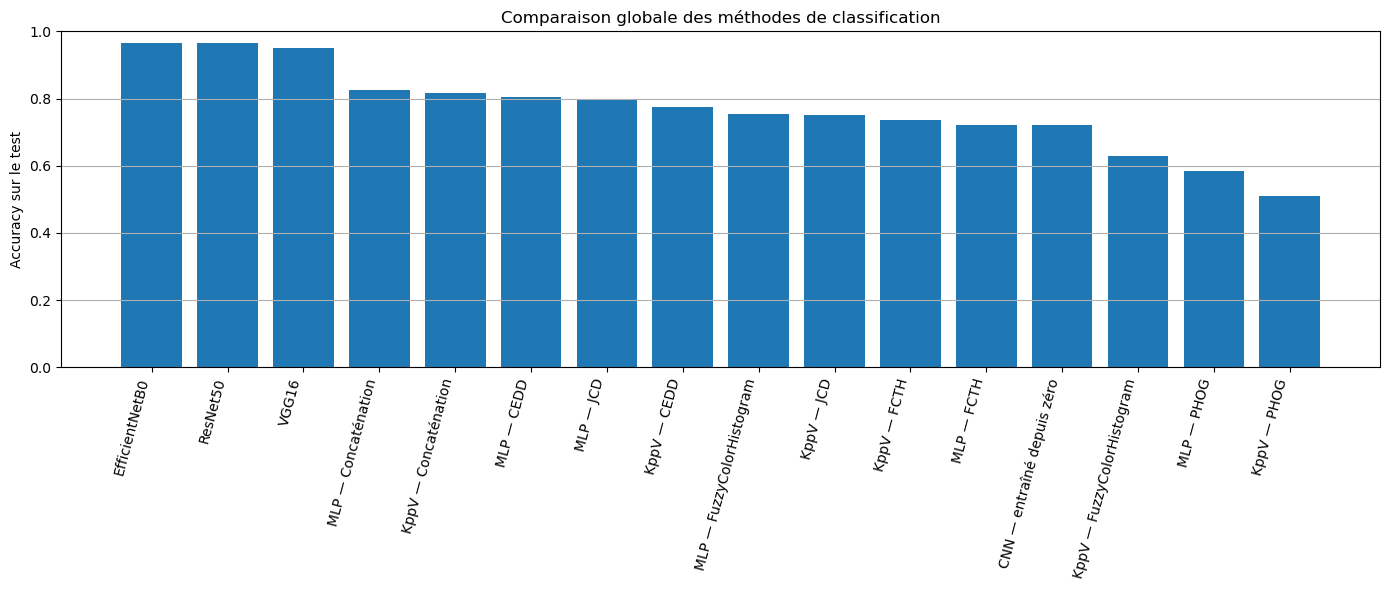

Meilleure approche : EfficientNetB0
Accuracy test : 0.9650
Taux d'erreur : 0.0350


In [38]:

# Résultats des MLP avec les différents descripteurs
global_mlp = pd.DataFrame({
    "Modèle": ["MLP — " + str(n) for n in tableau_mlp["Descripteur"]],
    "Accuracy test": tableau_mlp["Accuracy test"].to_numpy(),
    "Approche": "MLP — descripteurs"
})

# Résultats des KppV
global_knn = pd.DataFrame({
    "Modèle": ["KppV — " + str(n) for n in tableau_knn["Descripteur"]],
    "Accuracy test": tableau_knn["Accuracy test"].to_numpy(),
    "Approche": "KppV — descripteurs"
})

# CNN entraîné depuis zéro
global_cnn = pd.DataFrame([{
    "Modèle": "CNN — entraîné depuis zéro",
    "Accuracy test": float(accuracy_cnn),
    "Approche": "CNN"
}])

# VGG16 déjà évalué, sans nouvel entraînement
global_vgg = pd.DataFrame([{
    "Modèle": "VGG16",
    "Accuracy test": float(accuracy_vgg),
    "Approche": "Transfert d'apprentissage"
}])

# Nouveaux modèles
global_nouveaux = pd.DataFrame([
    {
        "Modèle": r["Modèle"],
        "Accuracy test": r["Accuracy test"],
        "Approche": "Transfert d'apprentissage"
    }
    for r in resultats_nouveaux
])

comparaison_globale = pd.concat(
    [global_mlp, global_knn, global_cnn, global_vgg, global_nouveaux],
    ignore_index=True
)

comparaison_globale["Taux d'erreur"] = (
    1 - comparaison_globale["Accuracy test"]
)

comparaison_globale = comparaison_globale.sort_values(
    "Accuracy test", ascending=False
).reset_index(drop=True)

display(comparaison_globale)

plt.figure(figsize=(14, 6))
plt.bar(
    comparaison_globale["Modèle"],
    comparaison_globale["Accuracy test"]
)
plt.ylabel("Accuracy sur le test")
plt.ylim(0, 1)
plt.title("Comparaison globale des méthodes de classification")
plt.xticks(rotation=75, ha="right")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

meilleur_global = comparaison_globale.iloc[0]
print("Meilleure approche :", meilleur_global["Modèle"])
print(f"Accuracy test : {meilleur_global['Accuracy test']:.4f}")
taux_erreur = meilleur_reseau["Taux d'erreur"]
print(f"Taux d'erreur : {taux_erreur:.4f}")

## Conclusion générale

Ce TP nous a permis de comparer plusieurs approches de classification d’images sur la base Wang. Les résultats montrent que le **transfert d’apprentissage est l’approche la plus performante** : ResNet50 et EfficientNetB0 atteignent une accuracy de **96,5 %**, suivis de VGG16 avec **93,5 %**. Le MLP utilisant la concaténation des descripteurs obtient **87 %**, tandis que le CNN entraîné depuis zéro atteint **72 %**.

Ces résultats soulignent l’intérêt des caractéristiques pré-entraînées et de la combinaison de plusieurs descripteurs pour améliorer la classification. En conclusion, **ResNet50 et EfficientNetB0 offrent les meilleures performances sur ce jeu de données**, avec seulement 3,5 % d’erreurs sur l’ensemble de test.